# Phase 3 (Walk+): Model Validation & Statistical Backtesting Suite
**Multi-Asset Macro Trading Desk ($10,000,000 Notional | 1,500-Day Out-of-Sample Window: 2020–2025)**

### Executive Objective
This notebook subjects all eight VaR estimators (including **$\text{EGARCH}(1,1)$ Filtered Historical Simulation**) to formal regulatory backtesting over **1,500 out-of-sample trading days** (expected 99% breaches = $15.0$):
1. **Basel Committee Traffic Light Framework:** Green ($0\text{–}4$), Yellow ($5\text{–}9$), and Red ($\ge 10$ breaches) zones.
2. **Kupiec (1995) Proportion of Failures (POF) Test ($LR_{UC} \sim \chi^2_1$)**.
3. **Christoffersen (1998) Markov Independence ($LR_{IND} \sim \chi^2_1$) & Conditional Coverage ($LR_{CC} \sim \chi^2_2$)**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data
from src.volatility_models import build_dynamic_var_series
from src.backtesting import run_champion_challenger_backtest, generate_hit_sequence

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 5.5)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
portfolio_df = bundle["portfolio"]
notional_usd = float(cfg["portfolio"]["notional_usd"])

dyn_df, _ = build_dynamic_var_series(
    portfolio_df["portfolio_arith_return"],
    alpha=0.99,
    lookback_days=250,
    notional_usd=notional_usd,
)

validation_table, rolling_breaches_df = run_champion_challenger_backtest(
    dyn_df, alpha=0.99, oos_days=1500, basel_window=250
)
validation_table[[
    "OOS_Days", "Expected_Breaches", "Total_Breaches", "Breach_Rate_pct", "Clustered_Pairs_n11",
    "Latest_250d_Breaches", "Latest_Basel_Zone", "LR_UC", "p_val_UC", "LR_IND", "p_val_IND", "LR_CC", "p_val_CC", "Validation_Verdict"
]].round(3)

,OOS_Days,Expected_Breaches,Total_Breaches,Breach_Rate_pct,Clustered_Pairs_n11,Latest_250d_Breaches,Latest_Basel_Zone,LR_UC,p_val_UC,LR_IND,p_val_IND,LR_CC,p_val_CC,Validation_Verdict
Model,,,,,,,,,,,,,,
Plain Historical Sim (250d),1500,15.0,22,1.467,2,4,Green,2.885,0.089,4.209,0.040,7.093,0.029,FAIL Independence (Clustered Breaches)
Static Rolling Normal (250d),1500,15.0,35,2.333,4,6,Yellow,19.581,0.000,6.959,0.008,26.540,0.000,FAIL Both Coverage & Independence
RiskMetrics EWMA Normal (λ=0.94),1500,15.0,29,1.933,0,4,Green,10.369,0.001,1.144,0.285,11.513,0.003,FAIL Coverage (Excessive Breaches)
"GARCH(1,1) Normal",1500,15.0,33,2.200,0,5,Yellow,16.257,0.000,1.486,0.223,17.743,0.000,FAIL Coverage (Excessive Breaches)
"GARCH(1,1) Student-t",1500,15.0,22,1.467,0,2,Green,2.885,0.089,0.655,0.418,3.540,0.170,PASS (Champion Tier)
"EGARCH(1,1) Filtered HS (FHS)",1500,15.0,18,1.200,0,2,Green,0.570,0.450,0.438,0.508,1.007,0.604,PASS (Champion Tier)
"Age-Weighted HS (BRW, λ=0.98)",1500,15.0,21,1.400,0,2,Green,2.156,0.142,0.597,0.440,2.753,0.252,PASS (Champion Tier)
Hull-White Volatility-Weighted HS,1500,15.0,18,1.200,0,1,Green,0.570,0.450,0.438,0.508,1.007,0.604,PASS (Champion Tier)


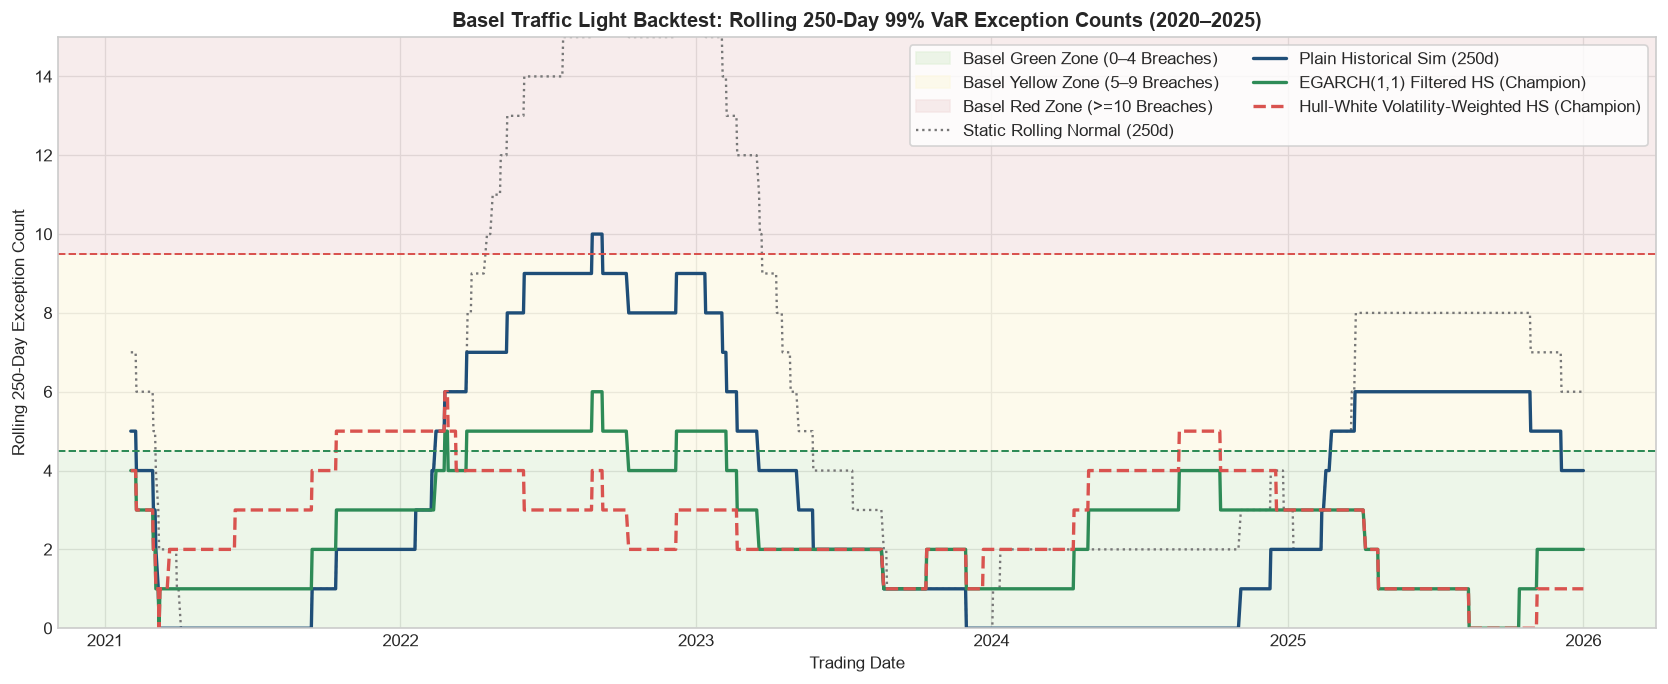

In [2]:
fig, ax = plt.subplots(figsize=(14, 5.8))
ax.axhspan(0, 4.5, color="#dff0d8", alpha=0.55, label="Basel Green Zone (0–4 Breaches)")
ax.axhspan(4.5, 9.5, color="#fcf8e3", alpha=0.65, label="Basel Yellow Zone (5–9 Breaches)")
ax.axhspan(9.5, 16.0, color="#f2dede", alpha=0.55, label="Basel Red Zone (>=10 Breaches)")

ax.plot(rolling_breaches_df.index, rolling_breaches_df["Static Rolling Normal (250d)"], color="#777777", lw=1.4, ls=":", label="Static Rolling Normal (250d)")
ax.plot(rolling_breaches_df.index, rolling_breaches_df["Plain Historical Sim (250d)"], color="#1f4e78", lw=2.0, label="Plain Historical Sim (250d)")
ax.plot(rolling_breaches_df.index, rolling_breaches_df["EGARCH(1,1) Filtered HS (FHS)"], color="#2e8b57", lw=2.0, label="EGARCH(1,1) Filtered HS (Champion)")
ax.plot(rolling_breaches_df.index, rolling_breaches_df["Hull-White Volatility-Weighted HS"], color="#d9534f", lw=2.0, ls="--", label="Hull-White Volatility-Weighted HS (Champion)")

ax.axhline(4.5, color="#2e8b57", lw=1.2, ls="--")
ax.axhline(9.5, color="#d9534f", lw=1.2, ls="--")
ax.set_ylim(0, 15)
ax.set_title("Basel Traffic Light Backtest: Rolling 250-Day 99% VaR Exception Counts (2020–2025)", fontweight="bold")
ax.set_ylabel("Rolling 250-Day Exception Count")
ax.set_xlabel("Trading Date")
ax.legend(loc="upper right", ncol=2, frameon=True)
plt.tight_layout()
plt.show()

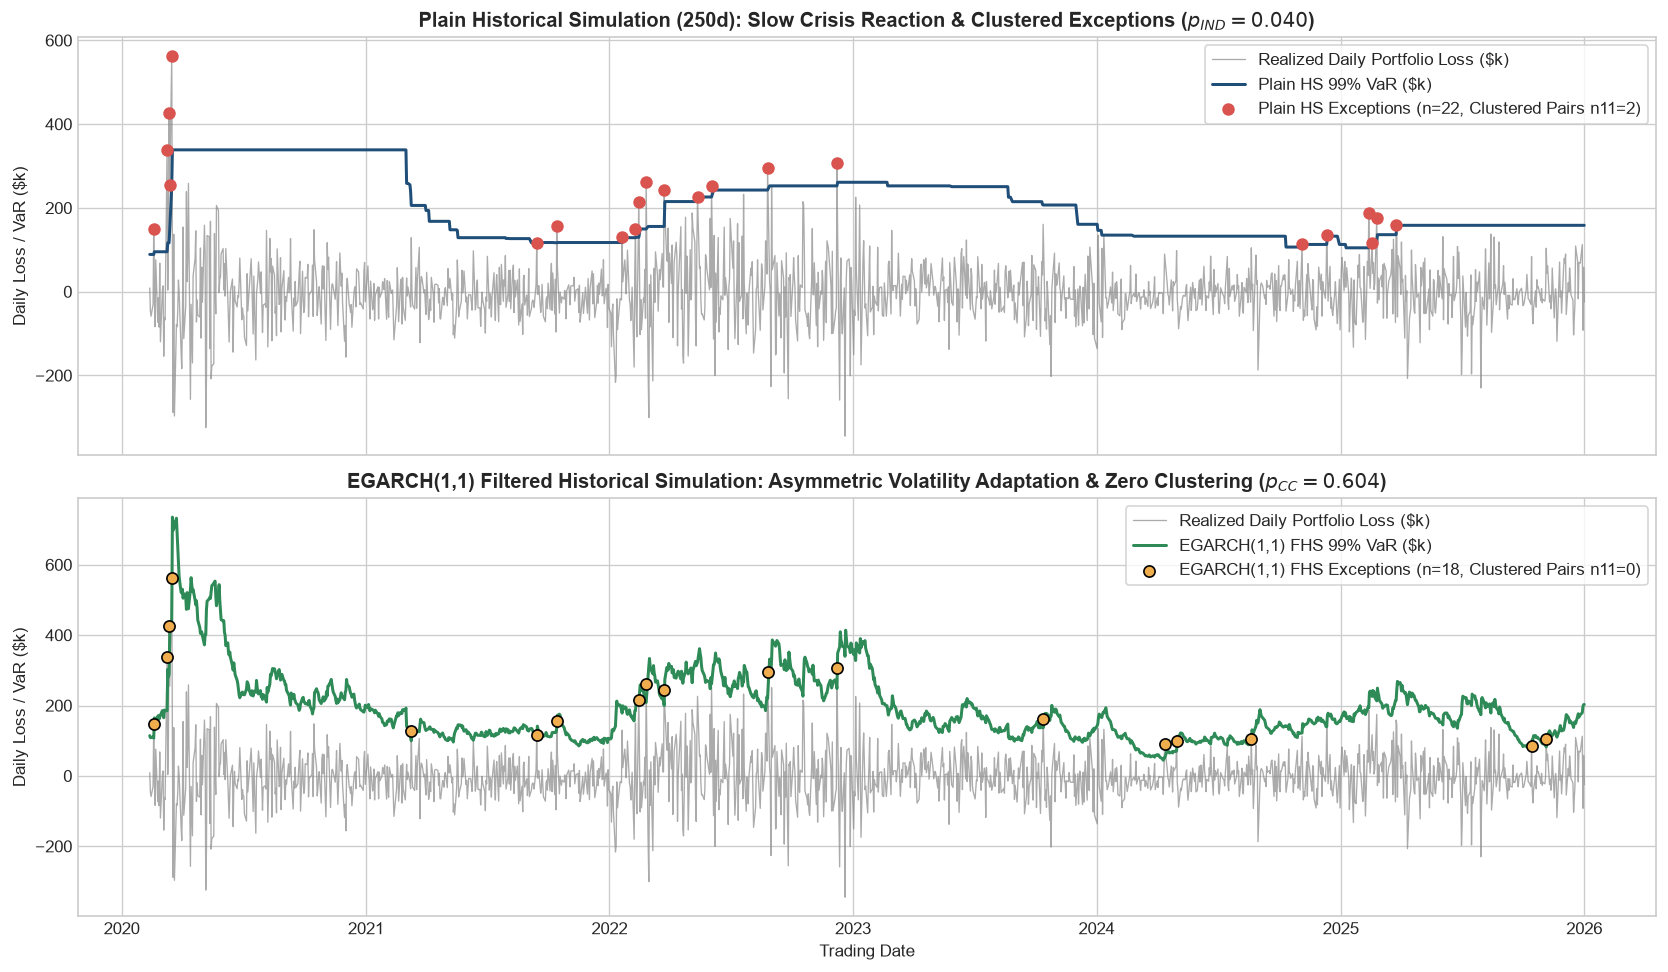

In [3]:
oos_df = dyn_df.iloc[-1500:].copy()
hits_plain = generate_hit_sequence(oos_df["Realized_Loss_USD"], oos_df["Plain_HS_250d_VaR_USD"])
hits_egarch = generate_hit_sequence(oos_df["Realized_Loss_USD"], oos_df["EGARCH11_FHS_VaR_USD"])

breach_dates_plain = oos_df.index[hits_plain == 1]
breach_dates_egarch = oos_df.index[hits_egarch == 1]

fig, axes = plt.subplots(2, 1, figsize=(14, 8.2), sharex=True)

axes[0].plot(oos_df.index, oos_df["Realized_Loss_USD"] / 1e3, color="#888888", lw=0.8, alpha=0.7, label="Realized Daily Portfolio Loss ($k)")
axes[0].plot(oos_df.index, oos_df["Plain_HS_250d_VaR_USD"] / 1e3, color="#1f4e78", lw=1.8, label="Plain HS 99% VaR ($k)")
axes[0].scatter(
    breach_dates_plain, oos_df.loc[breach_dates_plain, "Realized_Loss_USD"] / 1e3,
    color="#d9534f", s=42, zorder=5, label=f"Plain HS Exceptions (n={len(breach_dates_plain)}, Clustered Pairs n11=2)"
)
axes[0].set_title("Plain Historical Simulation (250d): Slow Crisis Reaction & Clustered Exceptions ($p_{IND} = 0.040$)", fontweight="bold")
axes[0].set_ylabel("Daily Loss / VaR ($k)")
axes[0].legend(loc="upper right", frameon=True)

axes[1].plot(oos_df.index, oos_df["Realized_Loss_USD"] / 1e3, color="#888888", lw=0.8, alpha=0.7, label="Realized Daily Portfolio Loss ($k)")
axes[1].plot(oos_df.index, oos_df["EGARCH11_FHS_VaR_USD"] / 1e3, color="#2e8b57", lw=1.8, label="EGARCH(1,1) FHS 99% VaR ($k)")
axes[1].scatter(
    breach_dates_egarch, oos_df.loc[breach_dates_egarch, "Realized_Loss_USD"] / 1e3,
    color="#f0ad4e", edgecolors="black", s=45, zorder=5, label=f"EGARCH(1,1) FHS Exceptions (n={len(breach_dates_egarch)}, Clustered Pairs n11=0)"
)
axes[1].set_title("EGARCH(1,1) Filtered Historical Simulation: Asymmetric Volatility Adaptation & Zero Clustering ($p_{CC} = 0.604$)", fontweight="bold")
axes[1].set_ylabel("Daily Loss / VaR ($k)")
axes[1].set_xlabel("Trading Date")
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()